<a href="https://colab.research.google.com/github/Sibuninja/ML_LAB_ASSIGNMENT/blob/ASSIGNMENT-4/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
# Load Digits dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", len(np.unique(y)))

Dataset Shape: (1797, 64)
Target Shape: (1797,)
Number of Features: 64
Number of Classes: 10


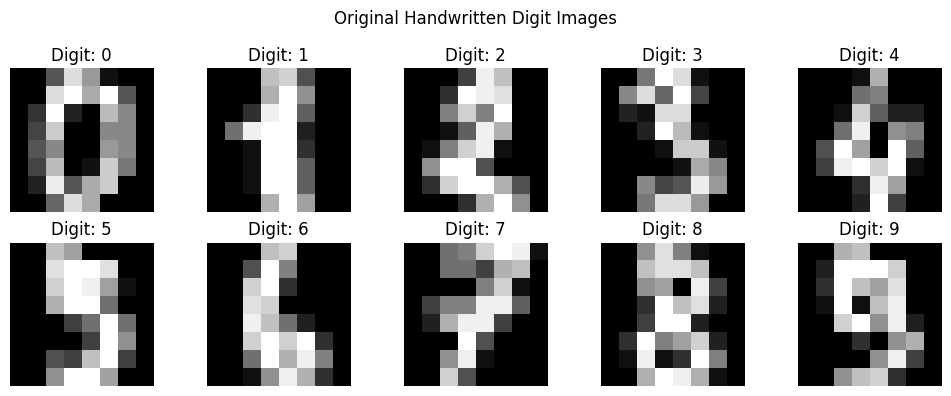

In [17]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title(f"Digit: {y[i]}")
    plt.axis('off')

plt.suptitle("Original Handwritten Digit Images")
plt.tight_layout()
plt.show()

In [18]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Data Shape:", X.shape)
print("Scaled Data Shape:", X_scaled.shape)

print("Mean:", np.round(X_scaled.mean(), 4))
print("Standard Deviation:", np.round(X_scaled.std(), 4))

Original Data Shape: (1797, 64)
Scaled Data Shape: (1797, 64)
Mean: 0.0
Standard Deviation: 0.9763


In [19]:
def pca_from_scratch(X, n_components):

    # Step 1: Calculate mean
    mean = np.mean(X, axis=0)

    # Step 2: Center the data
    X_centered = X - mean

    # Step 3: Calculate covariance matrix
    covariance_matrix = np.cov(X_centered, rowvar=False)

    # Step 4: Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

    # Step 5: Sort eigenvalues in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]

    # Step 6: Select principal components
    principal_components = eigenvectors[:, :n_components]

    # Step 7: Project data
    X_pca = X_centered @ principal_components

    # Explained variance ratio
    explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

    return (
        X_pca,
        principal_components,
        mean,
        eigenvalues,
        explained_variance_ratio
    )


print("PCA function implemented successfully!")

PCA function implemented successfully!


In [20]:
X_pca, components, mean, eigenvalues, variance_ratio = pca_from_scratch(
    X_scaled,
    n_components=2
)

print("Original Shape:", X_scaled.shape)
print("Reduced Shape:", X_pca.shape)

print("\nFirst Two Principal Components:")
print(components)

print("\nExplained Variance Ratio:")
print(variance_ratio[:2])

print("\nTotal Variance Explained:")
print(np.sum(variance_ratio[:2]) * 100, "%")

Original Shape: (1797, 64)
Reduced Shape: (1797, 2)

First Two Principal Components:
[[ 0.          0.        ]
 [-0.18223392  0.04702701]
 [-0.285868    0.0595648 ]
 [-0.22036967 -0.02080385]
 [ 0.02516956  0.15590316]
 [ 0.00949725  0.27413299]
 [ 0.0524765   0.24973251]
 [ 0.06269499  0.14583207]
 [-0.03470727 -0.00102721]
 [-0.24553368  0.02761909]
 [-0.22915174  0.01450474]
 [ 0.10794381 -0.09225537]
 [-0.03620209  0.0572917 ]
 [-0.03871159  0.21410852]
 [ 0.08378077  0.26653585]
 [ 0.09277502  0.13699943]
 [-0.01669934 -0.00733687]
 [-0.1367165  -0.02014035]
 [ 0.06305075 -0.11844133]
 [ 0.12287927 -0.08408699]
 [-0.14819348  0.07684584]
 [ 0.02348425  0.15949153]
 [ 0.1711997   0.14605982]
 [ 0.10420837  0.08083712]
 [ 0.00394882 -0.00388437]
 [ 0.1163897  -0.06552741]
 [ 0.18820473 -0.11263765]
 [-0.0658604   0.05368068]
 [-0.14353257  0.16490377]
 [ 0.12820705  0.13773838]
 [ 0.18062075  0.056104  ]
 [ 0.05270917  0.02670685]
 [ 0.          0.        ]
 [ 0.23890251 -0.1176814

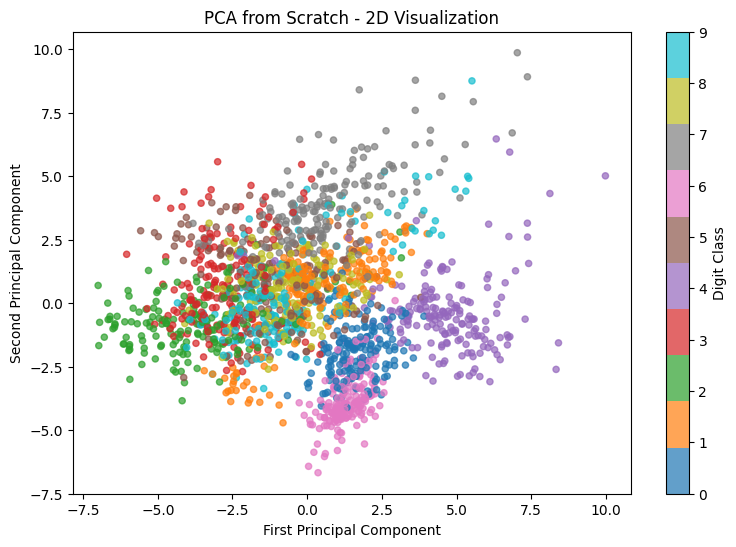

In [21]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='tab10',
    s=20,
    alpha=0.7
)

plt.colorbar(scatter, label="Digit Class")

plt.title("PCA from Scratch - 2D Visualization")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")

plt.show()

In [22]:
# Reconstruct data
X_reconstructed = X_pca @ components.T + mean

print("Original Data Shape:", X_scaled.shape)
print("Reconstructed Data Shape:", X_reconstructed.shape)

# Calculate reconstruction error
reconstruction_error = np.mean(
    (X_scaled - X_reconstructed) ** 2
)

print("\nReconstruction Error (MSE):", reconstruction_error)

Original Data Shape: (1797, 64)
Reconstructed Data Shape: (1797, 64)

Reconstruction Error (MSE): 0.7472979374139382


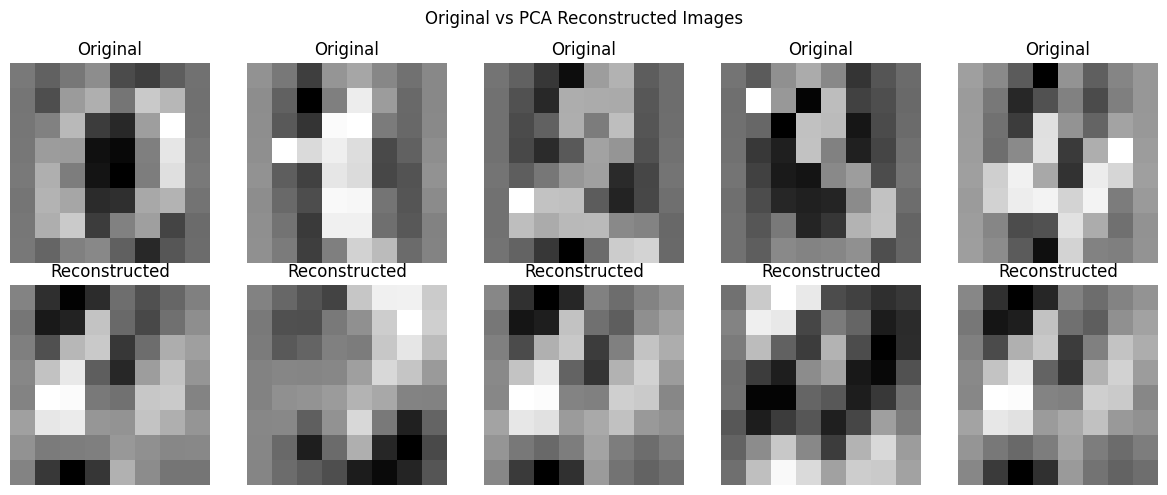

In [23]:
plt.figure(figsize=(12, 5))

for i in range(5):

    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_scaled[i].reshape(8, 8), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 5, i + 6)
    plt.imshow(X_reconstructed[i].reshape(8, 8), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.suptitle("Original vs PCA Reconstructed Images")
plt.tight_layout()
plt.show()

In [24]:
sklearn_pca = PCA(n_components=2)

X_sklearn_pca = sklearn_pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("Reduced Shape:", X_sklearn_pca.shape)

print("\nScikit-learn Explained Variance Ratio:")
print(sklearn_pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(
    np.sum(sklearn_pca.explained_variance_ratio_) * 100,
    "%"
)

Original Shape: (1797, 64)
Reduced Shape: (1797, 2)

Scikit-learn Explained Variance Ratio:
[0.12033916 0.09561054]

Total Variance Explained:
21.594970500832787 %


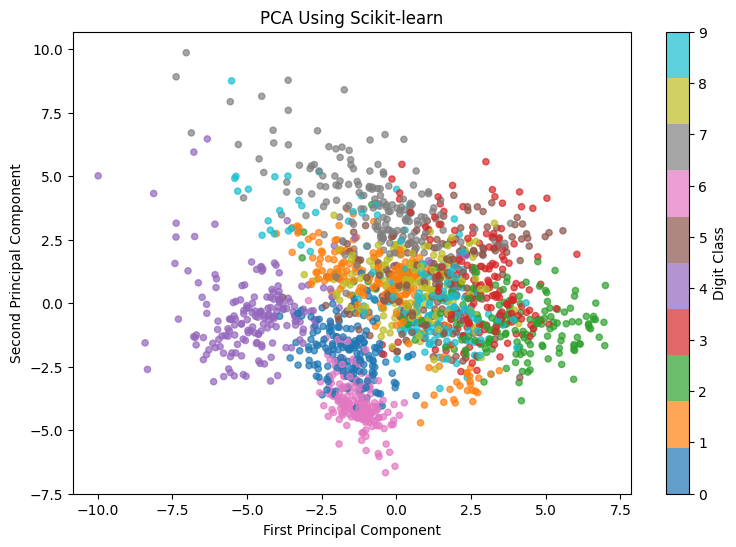

In [25]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_sklearn_pca[:, 0],
    X_sklearn_pca[:, 1],
    c=y,
    cmap='tab10',
    s=20,
    alpha=0.7
)

plt.colorbar(scatter, label="Digit Class")

plt.title("PCA Using Scikit-learn")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")

plt.show()

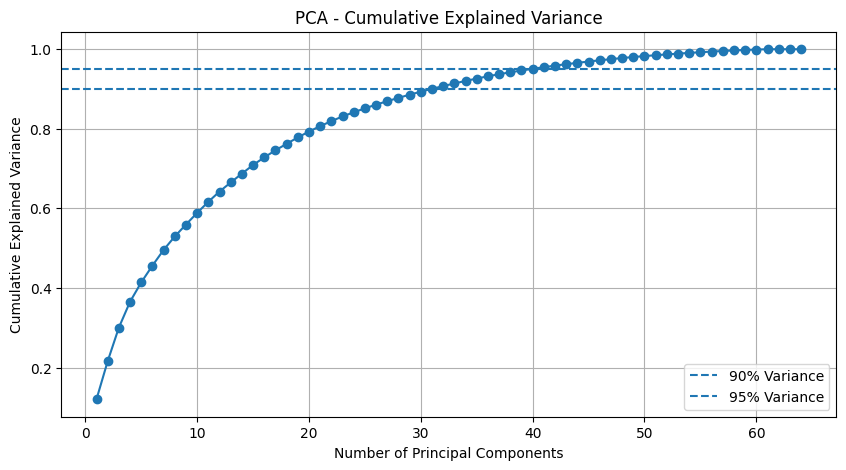

In [26]:
# Calculate PCA for all components
pca_all = PCA()

pca_all.fit(X_scaled)

explained_variance = pca_all.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)

plt.axhline(y=0.90, linestyle='--', label='90% Variance')
plt.axhline(y=0.95, linestyle='--', label='95% Variance')

plt.legend()
plt.show()

Components: 2 | Reconstruction Error: 0.7473
Components: 5 | Reconstruction Error: 0.55855
Components: 10 | Reconstruction Error: 0.39198
Components: 20 | Reconstruction Error: 0.19717
Components: 30 | Reconstruction Error: 0.10179
Components: 40 | Reconstruction Error: 0.04691
Components: 50 | Reconstruction Error: 0.01643
Components: 64 | Reconstruction Error: 0.0


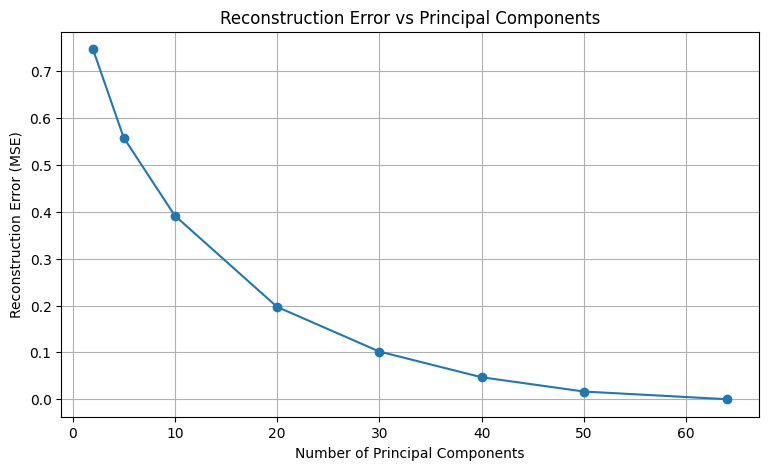

In [27]:
components_list = [2, 5, 10, 20, 30, 40, 50, 64]

errors = []

for n in components_list:

    pca = PCA(n_components=n)

    reduced = pca.fit_transform(X_scaled)

    reconstructed = pca.inverse_transform(reduced)

    error = np.mean((X_scaled - reconstructed) ** 2)

    errors.append(error)

    print(
        "Components:", n,
        "| Reconstruction Error:", round(error, 5)
    )

plt.figure(figsize=(9, 5))

plt.plot(
    components_list,
    errors,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Reconstruction Error (MSE)")

plt.title("Reconstruction Error vs Principal Components")
plt.grid(True)

plt.show()

In [28]:
print("========== PCA COMPARISON ==========")

print("\nPCA From Scratch:")
print("Reduced Shape:", X_pca.shape)
print("Explained Variance Ratio:", variance_ratio[:2])
print("Total Variance Explained:",
      round(np.sum(variance_ratio[:2]) * 100, 2), "%")
print("Reconstruction Error:",
      round(reconstruction_error, 5))

print("\nScikit-learn PCA:")
print("Reduced Shape:", X_sklearn_pca.shape)
print("Explained Variance Ratio:",
      sklearn_pca.explained_variance_ratio_)
print("Total Variance Explained:",
      round(np.sum(sklearn_pca.explained_variance_ratio_) * 100, 2), "%")

print("\nPCA implementation and comparison completed successfully!")

========== PCA COMPARISON ==========

PCA From Scratch:
Reduced Shape: (1797, 2)
Explained Variance Ratio: [0.12033916 0.09561054]
Total Variance Explained: 21.59 %
Reconstruction Error: 0.7473

Scikit-learn PCA:
Reduced Shape: (1797, 2)
Explained Variance Ratio: [0.12033916 0.09561054]
Total Variance Explained: 21.59 %

PCA implementation and comparison completed successfully!
